# How many primes are there? From proportions to Gauss's guess

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapters "How many primes are there?", "Prime numbers viewed from a distance", "Pure and applied mathematics" and "A probabilistic first guess".*

> Slow as we are to understand primes, at the very least we can try to count them. You can see that there are $10$ primes less than $30$, so you might encapsulate this by saying that the chances that a number less than $30$ is prime is $1$ in $3$. This frequency does not persist, though …

Write $\pi(X)$ for the number of primes up to $X$. In this notebook you will:

1. watch the **proportion** of primes $\pi(X)/X$ shrink, and see that "1 in $N$" grows like $\log X$;
2. meet **Gauss's guess**, that a number near $x$ is prime with "probability" $1/\log x$, and the area under $1/\log t$ that it leads to;
3. compare $\pi(X)$ with $X/\log X$ and with $\operatorname{Li}(X) = \int_2^X dt/\log t$, from close up and from far away;
4. see what **"asymptotic"** means, which is the language of the Prime Number Theorem.

In [1]:
import numpy as np

def prime_pi_table(B):
    "pi(n) for n = 0, 1, ..., B: one sieve, then a running count."
    is_prime = np.zeros(B + 1)
    is_prime[np.array(prime_range(B + 1))] = 1
    return np.cumsum(is_prime)

PI = prime_pi_table(10^6)

def staircase(X):
    "The graph of pi(x) for 0 <= x <= X as a staircase: a step up at each prime."
    pts, k = [(0, 0)], 0
    for p in prime_range(X + 1):
        pts += [(p, k), (p, k + 1)]
        k += 1
    pts.append((X, k))
    return pts

## 1. The proportion of primes

The fraction of the numbers up to $X$ that are prime, $\pi(X)/X$, falls as $X$ grows, but more and more slowly. The dashed curve is $1/\log X$, the guess this notebook builds up to.

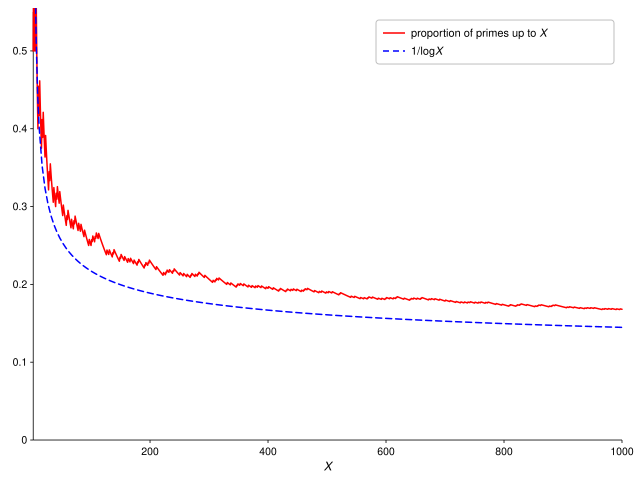

In [2]:
@interact
def proportion(X=selector([100, 1000, 10^4, 10^5], default=1000, label='X up to'),
               guess=checkbox(True, label='show 1/log(X)')):
    step = max(1, X // 3000)
    pts = [(n, PI[n] / n) for n in range(2, X + 1, step)]
    g = list_plot(pts, plotjoined=True, color='red', legend_label='proportion of primes up to $X$')
    if guess:
        g += plot(lambda t: 1 / log(t), (2, X), color='blue', linestyle='--', legend_label=r'$1/\log X$')
    show(g, axes_labels=['$X$', ''], ymin=0, ymax=0.55)

The book reads these proportions as odds: up to $30$, about $1$ in $3$ numbers is prime; up to $100$, $1$ in $4$; up to a thousand, $1$ in $6$; up to a million, $1$ in $13$; up to ten billion, $1$ in $22$. Every time $X$ is multiplied by ten, the odds get worse by about $2.3$, and $2.3 \approx \log 10$: the odds are about **$1$ in $\log X$**.

(A small correction to the book, which gives $\pi(\text{ten billion})$ as $455{,}052{,}512$: the count is $455{,}052{,}511$.)

In [3]:
# pi(10^k), from OEIS A006880
PI_10 = {1: 4, 2: 25, 3: 168, 4: 1229, 5: 9592, 6: 78498, 7: 664579, 8: 5761455, 9: 50847534,
         10: 455052511, 11: 4118054813, 12: 37607912018, 13: 346065536839, 14: 3204941750802,
         15: 29844570422669, 16: 279238341033925, 17: 2623557157654233, 18: 24739954287740860}
rows = [['$X$', r'$\pi(X)$', r'odds: $1$ in $X/\pi(X)$', r'$\log X$']]
for k, p in PI_10.items():
    rows.append(['$10^{%d}$' % k, p, '%.2f' % (10^k / p), '%.2f' % log(10.0^k)])
table(rows, header_row=True)

| $X$ | $\pi(X)$ | odds: $1$ in $X/\pi(X)$ | $\log X$ |
|:---|:---|:---|:---|
| $10^{1}$ | $4$ | 2.50 | 2.30 |
| $10^{2}$ | $25$ | 4.00 | 4.61 |
| $10^{3}$ | $168$ | 5.95 | 6.91 |
| $10^{4}$ | $1229$ | 8.14 | 9.21 |
| $10^{5}$ | $9592$ | 10.43 | 11.51 |
| $10^{6}$ | $78498$ | 12.74 | 13.82 |
| $10^{7}$ | $664579$ | 15.05 | 16.12 |
| $10^{8}$ | $5761455$ | 17.36 | 18.42 |
| $10^{9}$ | $50847534$ | 19.67 | 20.72 |
| $10^{10}$ | $455052511$ | 21.98 | 23.03 |
| $10^{11}$ | $4118054813$ | 24.28 | 25.33 |
| $10^{12}$ | $37607912018$ | 26.59 | 27.63 |
| $10^{13}$ | $346065536839$ | 28.90 | 29.93 |
| $10^{14}$ | $3204941750802$ | 31.20 | 32.24 |
| $10^{15}$ | $29844570422669$ | 33.51 | 34.54 |
| $10^{16}$ | $279238341033925$ | 35.81 | 36.84 |
| $10^{17}$ | $2623557157654233$ | 38.12 | 39.14 |
| $10^{18}$ | $24739954287740860$ | 40.42 | 41.45 |

## 2. Gauss's guess, and the area under $1/\log t$

> If you make believe that the chances that a number $X$ is a prime is inversely proportional to the number of digits of $X$ you might well hit upon Gauss's curve.

If a number near $t$ is prime with "probability" $1/\log t$, the expected number of primes up to $X$ is the **area under the curve $1/\log t$**, from $2$ to $X$:
$$\operatorname{Li}(X) = \int_2^X \frac{dt}{\log t}.$$
Below, the primes are dots on the axis (bigger for smaller primes, as $1/\log p$), and the shaded area is $\operatorname{Li}(X)$. Compare the two numbers.

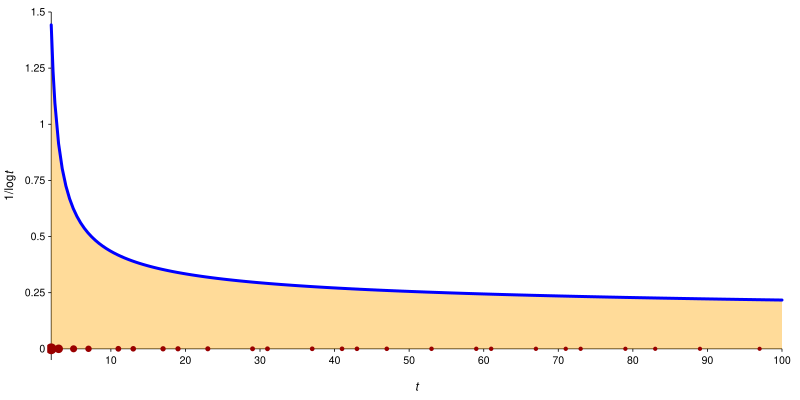

area under 1/log t from 2 to 100: 29.08
number of primes up to 100:       25


In [4]:
from scipy.special import expi

def Li(x):
    "Li(x) = integral from 2 to x of dt/log t = li(x) - li(2)."
    return expi(float(log(x))) - expi(float(log(2)))

@interact
def area(X=selector([30, 100, 1000], default=100, label='X')):
    curve = plot(lambda t: 1 / log(t), (2, X), color='blue', thickness=2)
    pts = [(t, 1 / log(t)) for t in np.linspace(2, X, 400)]
    shade = polygon([(2, 0)] + pts + [(X, 0)], color='orange', alpha=0.4)
    dots = sum(point((p, 0), color=(0.6, 0, 0), size=float(25 / log(p))) for p in prime_range(X + 1))
    # (a polygon asks for equal scales on both axes; this picture wants them independent)
    show(shade + curve + dots, axes_labels=['$t$', r'$1/\log t$'], ymin=-0.05, ymax=1.5, figsize=[8, 4], aspect_ratio='automatic')
    print('area under 1/log t from 2 to %d: %.2f' % (X, Li(X)))
    print('number of primes up to %d:       %d' % (X, PI[X]))

## 3. Three curves: $\pi(X)$, $X/\log X$ and $\operatorname{Li}(X)$

From close up, $\pi(X)$ is a staircase. From far away it is a smooth curve, and $\operatorname{Li}(X)$ (black) fits it astonishingly well, much better than the simpler $X/\log X$ (blue). The book also shows $X/(\log X - 1)$, which is better than $X/\log X$ but not as good as $\operatorname{Li}(X)$; turn it on to compare.

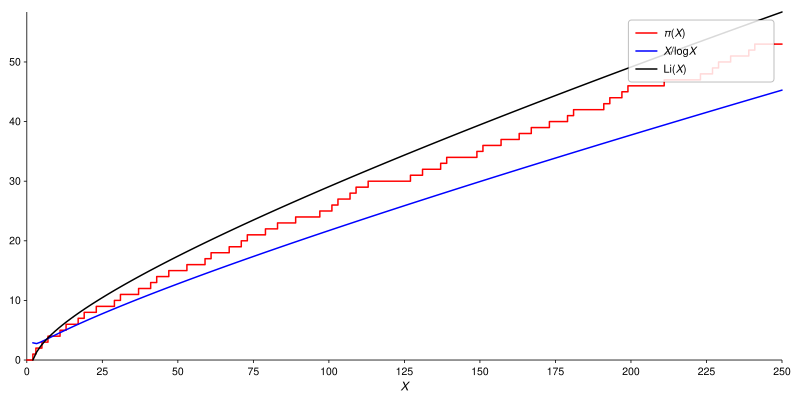

In [5]:
@interact
def three_curves(X=selector([50, 250, 1000, 10^4, 10^5, 10^6], default=250, label='X up to'),
                 legendre=checkbox(False, label='also X/(log X - 1)')):
    if X <= 10^4:
        g = line(staircase(X), color='red', legend_label=r'$\pi(X)$')
    else:
        step = X // 3000
        g = list_plot([(n, PI[n]) for n in range(2, X + 1, step)], plotjoined=True, color='red', legend_label=r'$\pi(X)$')
    g += plot(lambda t: t / log(t), (2, X), color='blue', legend_label=r'$X/\log X$')
    g += plot(Li, (2, X), color='black', legend_label=r'$\mathrm{Li}(X)$')
    if legendre:
        g += plot(lambda t: t / (log(t) - 1), (4, X), color='green', linestyle='--', legend_label=r'$X/(\log X - 1)$')
    show(g, axes_labels=['$X$', ''], figsize=[8, 4])

## 4. "Asymptotic": the language of the Prime Number Theorem

Two functions $A(X)$ and $B(X)$ are **asymptotic**, written $A(X) \sim B(X)$, if $A(X)/B(X) \to 1$ as $X \to \infty$. More generally, the book calls them of *similar rates of growth* if the ratio tends to some nonzero number: $A(X) = 2X^2 + 3X - 5$ and $B(X) = 3X^2 - 2X + 1$ are very different numbers, but $A(X)/B(X) \to 2/3$.

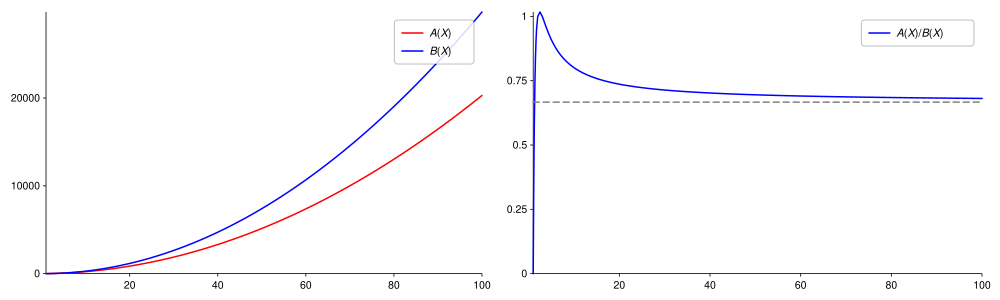

In [6]:
var('X')
A = 2*X^2 + 3*X - 5
B = 3*X^2 - 2*X + 1
both = plot(A, (X, 1, 100), color='red', legend_label='$A(X)$') + plot(B, (X, 1, 100), color='blue', legend_label='$B(X)$')
ratio = plot(A / B, (X, 1, 100), legend_label='$A(X)/B(X)$') + line([(1, 2/3), (100, 2/3)], color='gray', linestyle='--')
graphics_array([both, ratio]).show(figsize=[10, 3])

The **Prime Number Theorem** (Hadamard and de la Vallée Poussin, 1896) says that
$$\pi(X) \sim \frac{X}{\log X} \qquad\text{and}\qquad \pi(X) \sim \operatorname{Li}(X).$$
Both ratios tend to $1$, but at very different speeds. Using the known values of $\pi(10^k)$:

In [7]:
rows = [['$X$', r'$\pi(X) \big/ \frac{X}{\log X}$', r'$\pi(X) / \mathrm{Li}(X)$']]
for k, p in PI_10.items():
    x = 10.0^k
    rows.append(['$10^{%d}$' % k, '%.6f' % (p / (x / log(x))), '%.10f' % (p / Li(x))])
table(rows, header_row=True)

| $X$ | $\pi(X) \big/ \frac{X}{\log X}$ | $\pi(X) / \mathrm{Li}(X)$ |
|:---|:---|:---|
| $10^{1}$ | 0.921034 | 0.7811835193 |
| $10^{2}$ | 1.151293 | 0.8596684805 |
| $10^{3}$ | 1.160503 | 0.9514936780 |
| $10^{4}$ | 1.131951 | 0.9870756125 |
| $10^{5}$ | 1.104320 | 0.9961818736 |
| $10^{6}$ | 1.084490 | 0.9983656402 |
| $10^{7}$ | 1.071175 | 0.9994911249 |
| $10^{8}$ | 1.061299 | 0.9998692636 |
| $10^{9}$ | 1.053727 | 0.9999665696 |
| $10^{10}$ | 1.047797 | 0.9999931821 |
| $10^{11}$ | 1.043039 | 0.9999971864 |
| $10^{12}$ | 1.039145 | 0.9999989826 |
| $10^{13}$ | 1.035899 | 0.9999996851 |
| $10^{14}$ | 1.033151 | 0.9999999017 |
| $10^{15}$ | 1.030795 | 0.9999999647 |
| $10^{16}$ | 1.028752 | 0.9999999885 |
| $10^{17}$ | 1.026964 | 0.9999999970 |
| $10^{18}$ | 1.025385 | 0.9999999991 |

The first ratio is still $2.5\%$ away from $1$ at $10^{18}$; the second agrees to nine decimal places. How close $\pi(X)$ and $\operatorname{Li}(X)$ really are, and why, is exactly what the Riemann Hypothesis is about: see the notebook *How good is $\operatorname{Li}(x)$?*

## Things to try

1. The odds "1 in $X/\pi(X)$" grow by about $\log 10 \approx 2.30$ per power of ten. From the table, how close is the increase to $2.30$ at each step? Does it get closer?
2. In section 2, replace $1/\log t$ by $1/(\log t - 1)$ and compare the area with the number of primes. Better or worse?
3. Plot $\pi(X) - X/\log X$ and $\pi(X) - \operatorname{Li}(X)$ for $X$ up to $10^6$. Which one grows?

---
*Adapted and expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*